In [5]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

USE_COLAB = False
if USE_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)
    local_path = "/content/drive/MyDrive"
else:
    local_path = os.path.join(os.getcwd(),"../","Numerical Results")

In [6]:
test_Box = pd.read_csv(f"{local_path}/RisultatiBoxAlternatiVeri/dimensioni_frattali.csv")
test_Rete = pd.read_csv(f"{local_path}/RisultatiReteAlternatiExtra/dimensioni_frattali.csv")
test_No = pd.read_csv(f"{local_path}/RisultatiReteAlternatiExtraNoAug/dimensioni_frattali.csv")

In [7]:
# Reference model: always predicts the mean fractal dimension of the training set.
# The generator (Dataset Creation/Fractal_Curves.ipynb) draws kappa ~ U(KAPPA_MIN, KAPPA_MAX)
# and sets D = 1 + kappa/8, so E[D] is available in closed form:
#     E[D] = 1 + E[kappa]/8 = 1 + (KAPPA_MIN + KAPPA_MAX)/2 / 8
# The training split (15k curves) has a sample mean within sigma_D/sqrt(15000) ~ 1e-3 of this,
# which shifts the errors below by < 0.1 percentage points.
KAPPA_MIN, KAPPA_MAX = 0.0, 3.5
D_TRAIN_MEAN = ((1 + KAPPA_MIN / 8) + (1 + KAPPA_MAX / 8)) / 2
print(f"E[D] = {D_TRAIN_MEAN:.5f}")

D_MIN, D_MAX = 1 + KAPPA_MIN / 8, 1 + KAPPA_MAX / 8
# Mean relative error of the constant predictor, in percent. With D ~ U(D_MIN, D_MAX):
#   E[(E[D] - D)/D] = 1/(D_MAX - D_MIN) * Integral_{D_MIN}^{D_MAX} (E[D] - x)/x dx
#                   = ( E[D] * ln(D_MAX/D_MIN) - (D_MAX - D_MIN) ) / (D_MAX - D_MIN)
MEAN_ERR_REF = (
    (D_TRAIN_MEAN * np.log(D_MAX / D_MIN) - (D_MAX - D_MIN)) / (D_MAX - D_MIN) * 100
)
print(f"mean relative error of the constant predictor: {MEAN_ERR_REF:+.3f}%")

E[D] = 1.21875
mean relative error of the constant predictor: +1.095%


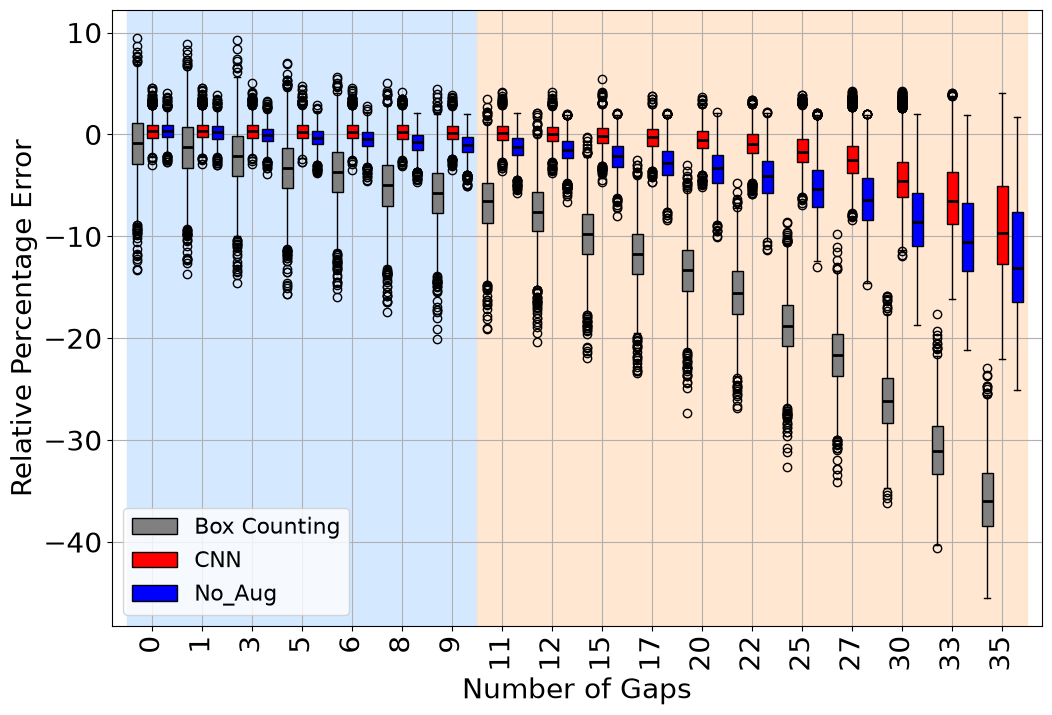

In [8]:
%matplotlib inline

porzione = [0, 1, 3, 5, 6, 8, 9, 11, 12, 15, 17, 20, 22, 25, 27, 30, 33, 35]

cols = [f"Errore_{k}" for k in range(18)]

data_Box = [test_Box[col].dropna().values for col in cols]
data_Rete = [test_Rete[col].dropna().values for col in cols]
data_No = [test_No[col].dropna().values for col in cols]

soglia = 7

fig, ax = plt.subplots(figsize=(12, 8))

x = np.arange(1, 19)

# offset to avoid overlap
offset = 0.3

bp1 = ax.boxplot(data_Box, positions=x - offset, widths=0.22,
                 patch_artist=True, boxprops=dict(facecolor="grey"), medianprops=dict(color="black", linewidth=2))
bp2 = ax.boxplot(data_Rete, positions=x, widths=0.22,
                 patch_artist=True, boxprops=dict(facecolor="red"), medianprops=dict(color="black", linewidth=2))
bp3 = ax.boxplot(data_No, positions=x + offset, widths=0.22,
                 patch_artist=True, boxprops=dict(facecolor="blue"), medianprops=dict(color="black", linewidth=2))

ax.axvspan(0.5, soglia + 0.5, color="#d0e7ff", alpha=0.9)
ax.axvspan(soglia + 0.5, len(x) + 0.5, color="#ffe5cc", alpha=0.9)

# Reference: analytic mean relative error of the constant predictor D = E[D]
# (independent of the number of points, so drawn as a horizontal line).
x_lo, x_hi = x.min() - 0.5, x.max() + 0.5
# line = ax.hlines(y=MEAN_ERR_REF, xmin=x_lo, xmax=x_hi, color="green", lw=3, ls="--", label="null model")

ax.set_xticks(x)
ax.set_xticklabels(porzione, rotation =90)
ax.tick_params(axis='both', labelsize=20)

ax.set_xlabel("Number of Gaps", fontsize=20)
ax.set_ylabel("Relative Percentage Error", fontsize=20)
ax.grid(True)


ax.legend([bp1["boxes"][0], bp2["boxes"][0],bp3["boxes"][0]],
          ["Box Counting", "CNN", "No_Aug"], loc="lower left", fontsize=16)

plt.show()